# Laboratory Exercise: Image Classification Using Pre-trained Models
**Environment:** Google Colab  
**Dataset:** Oxford-IIIT Pet Dataset (cats and dogs)  
**Task:** Compare five pre-trained `torchvision.models` using accuracy, precision, recall, and F1-score.



## 1. Import libraries

In [1]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import datasets, transforms, models
from torchvision.models import (
    ResNet18_Weights, MobileNet_V3_Small_Weights,
    EfficientNet_B0_Weights, AlexNet_Weights, VGG16_Weights
)

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


Device: cpu


## 2. Download and prepare the dataset

We use the **Oxford-IIIT Pet Dataset**, which includes cat and dog breeds. We convert each breed label into one of two classes: `cat` or `dog`.

The model input size and normalization are taken from each model's official pre-trained weights, so each model receives the input format it expects.


In [2]:
# Download the test split. The first run may take a few minutes.
base_dataset = datasets.OxfordIIITPet(
    root="/content/data",
    split="test",
    target_types="category",
    download=True
)

print("Number of images:", len(base_dataset))
print("First few breed labels:", base_dataset.classes[:10])


100%|██████████| 792M/792M [00:21<00:00, 36.4MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 16.3MB/s]


Number of images: 3669
First few breed labels: ['Abyssinian', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle', 'Bengal', 'Birman', 'Bombay', 'Boxer', 'British Shorthair']


In [3]:
# Breed names that belong to the cat class in Oxford-IIIT Pet.
cat_breeds = {
    "Abyssinian", "Bengal", "Birman", "Bombay", "British_Shorthair",
    "Egyptian_Mau", "Maine_Coon", "Persian", "Ragdoll", "Russian_Blue",
    "Siamese", "Sphynx"
}

class_names = ["cat", "dog"]

class CatDogDataset(Dataset):
    """Wrap Oxford-IIIT Pet and return an image plus a binary cat/dog label."""
    def __init__(self, dataset, transform=None):
        self.dataset = dataset
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, index):
        image, breed_label = self.dataset[index]
        breed_name = self.dataset.classes[breed_label]
        label = 0 if breed_name in cat_breeds else 1  # 0=cat, 1=dog

        if self.transform:
            image = self.transform(image)

        return image, label

# Use one consistent sample for every model.
# Select up to 100 cat images and 100 dog images for a quick comparison.
raw_labels = []
for _, breed_label in base_dataset:
    breed_name = base_dataset.classes[breed_label]
    raw_labels.append(0 if breed_name in cat_breeds else 1)

cat_indices = [i for i, label in enumerate(raw_labels) if label == 0]
dog_indices = [i for i, label in enumerate(raw_labels) if label == 1]

sample_count_per_class = min(100, len(cat_indices), len(dog_indices))
rng = random.Random(SEED)
chosen_indices = rng.sample(cat_indices, sample_count_per_class) + rng.sample(dog_indices, sample_count_per_class)
rng.shuffle(chosen_indices)

print("Cats:", sample_count_per_class, "| Dogs:", sample_count_per_class)
print("Total evaluation images:", len(chosen_indices))


Cats: 100 | Dogs: 100
Total evaluation images: 200


## 3. Create the DataLoader

Each model has its own official preprocessing transform. We use the same selected images for a fair comparison, but resize and normalize them according to each model's expected input requirements.


In [4]:
def make_loader(weights, indices, batch_size=16):
    preprocess = weights.transforms()
    wrapped_dataset = CatDogDataset(base_dataset, transform=preprocess)
    subset = Subset(wrapped_dataset, indices)
    return DataLoader(subset, batch_size=batch_size, shuffle=False, num_workers=2)

# Labels are the same regardless of model preprocessing.
y_true = [raw_labels[i] for i in chosen_indices]
print("Label mapping:", {0: "cat", 1: "dog"})


Label mapping: {0: 'cat', 1: 'dog'}


## 4. Load five pre-trained models

These models were trained on ImageNet, not specifically on this cat/dog dataset. We use their ImageNet predictions and map relevant ImageNet labels into `cat` or `dog`. Predictions that do not match a cat or dog label are treated as the model's more likely class only if its top prediction is a recognized cat/dog label; otherwise the notebook uses a simple fallback based on the strongest cat-vs-dog score across ImageNet labels.

This is **zero-shot evaluation**: no additional training is performed.


In [5]:
model_configs = [
    ("ResNet18", models.resnet18, ResNet18_Weights.DEFAULT),
    ("MobileNetV3-Small", models.mobilenet_v3_small, MobileNet_V3_Small_Weights.DEFAULT),
    ("EfficientNet-B0", models.efficientnet_b0, EfficientNet_B0_Weights.DEFAULT),
    ("AlexNet", models.alexnet, AlexNet_Weights.DEFAULT),
    ("VGG16", models.vgg16, VGG16_Weights.DEFAULT),
]

# ImageNet class names associated with cats and dogs.
# This broad matching captures common cat/dog labels in the ImageNet class list.
def is_cat_label(name):
    n = name.lower()
    return any(word in n for word in [
        "tabby", "tiger cat", "persian cat", "siamese cat", "egyptian cat",
        "cougar", "lynx", "leopard", "jaguar", "lion", "tiger", "cheetah",
        "house cat"
    ])

def is_dog_label(name):
    n = name.lower()
    dog_terms = [
        "dog", "terrier", "retriever", "shepherd", "spaniel", "hound",
        "poodle", "collie", "chihuahua", "husky", "malamute", "rottweiler",
        "doberman", "boxer", "beagle", "pug", "mastiff", "corgi", "dachshund",
        "schnauzer", "setter", "pointer", "samoyed", "akita", "basenji",
        "briard", "kelpie", "papillon", "pekinese", "pomeranian", "whippet",
        "wolfhound", "bloodhound", "basset", "affenpinscher", "eskimo dog"
    ]
    return any(word in n for word in dog_terms)

def get_cat_dog_indices(categories):
    cat_ids = [i for i, name in enumerate(categories) if is_cat_label(name)]
    dog_ids = [i for i, name in enumerate(categories) if is_dog_label(name)]
    return cat_ids, dog_ids

results = []
all_predictions = {}

for model_name, model_fn, weights in model_configs:
    print(f"Evaluating {model_name}...")
    model = model_fn(weights=weights).to(device)
    model.eval()

    categories = weights.meta["categories"]
    cat_ids, dog_ids = get_cat_dog_indices(categories)
    loader = make_loader(weights, chosen_indices)

    predictions = []
    with torch.no_grad():
        for images, _ in loader:
            images = images.to(device)
            logits = model(images)
            probs = torch.softmax(logits, dim=1)

            # Sum probability across ImageNet labels that indicate cat-like or dog-like classes.
            cat_score = probs[:, cat_ids].sum(dim=1)
            dog_score = probs[:, dog_ids].sum(dim=1)
            batch_preds = (dog_score > cat_score).long().cpu().numpy().tolist()
            predictions.extend(batch_preds)

    all_predictions[model_name] = predictions
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1-score": f1_score(y_true, predictions, zero_division=0),
    })

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

results_df = pd.DataFrame(results).sort_values("F1-score", ascending=False).reset_index(drop=True)
results_df.round(3)


Evaluating ResNet18...
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 134MB/s]


Evaluating MobileNetV3-Small...
Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 55.2MB/s]


Evaluating EfficientNet-B0...
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


...

Evaluating AlexNet...
Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 150MB/s]


Evaluating VGG16...
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:08<00:00, 64.1MB/s]


,Model,Accuracy,Precision,Recall,F1-score
0,VGG16,0.870,0.863,0.88,0.871
1,EfficientNet-B0,0.860,0.846,0.88,0.863
2,MobileNetV3-Small,0.855,0.838,0.88,0.859
3,ResNet18,0.850,0.830,0.88,0.854
4,AlexNet,0.815,0.779,0.88,0.826


## 5. Compare results in a table and chart

The metrics treat `dog` as the positive class. Precision measures how many predicted dogs were actually dogs; recall measures how many actual dogs were detected; F1-score balances precision and recall.


,Model,Accuracy,Precision,Recall,F1-score
0,VGG16,0.870,0.863,0.88,0.871
1,EfficientNet-B0,0.860,0.846,0.88,0.863
2,MobileNetV3-Small,0.855,0.838,0.88,0.859
3,ResNet18,0.850,0.830,0.88,0.854
4,AlexNet,0.815,0.779,0.88,0.826


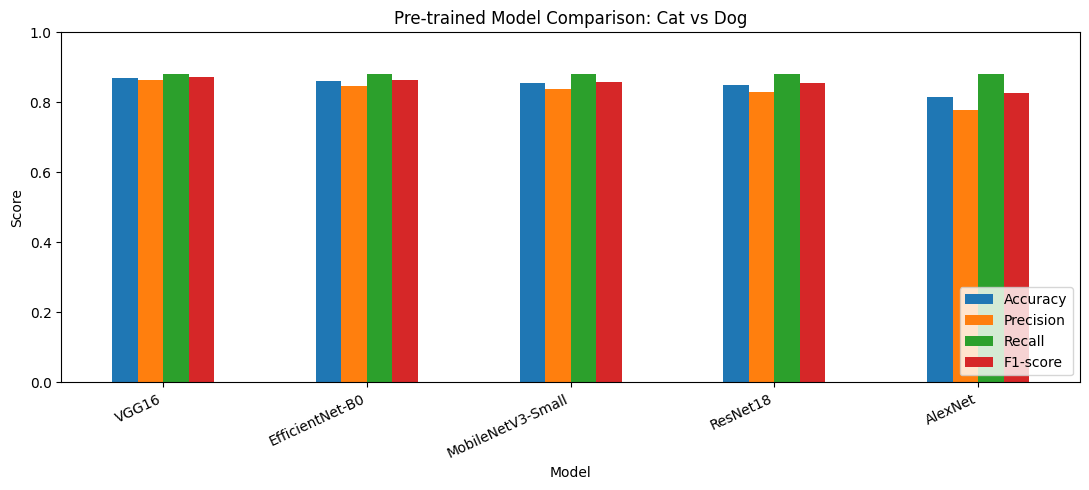

In [6]:
display(results_df.round(3))

plot_df = results_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1-score"]]
ax = plot_df.plot(kind="bar", figsize=(11, 5), ylim=(0, 1))
ax.set_title("Pre-trained Model Comparison: Cat vs Dog")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
plt.xticks(rotation=25, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


## 6. Classification report for the best F1-score model

In [7]:
best_model = results_df.iloc[0]["Model"]
print("Best model by F1-score:", best_model)
print(classification_report(
    y_true,
    all_predictions[best_model],
    labels=[0, 1],
    target_names=["cat", "dog"],
    zero_division=0
))


Best model by F1-score: VGG16
              precision    recall  f1-score   support

         cat       0.88      0.86      0.87       100
         dog       0.86      0.88      0.87       100

    accuracy                           0.87       200
   macro avg       0.87      0.87      0.87       200
weighted avg       0.87      0.87      0.87       200



## 7. Short analysis and conclusion

**Analysis template:** After running the notebook, use the printed table and chart to identify the model with the highest accuracy and F1-score. The five models may perform differently because their architectures and ImageNet training differ. ResNet18 uses residual connections, MobileNetV3-Small is designed to be lightweight, EfficientNet-B0 balances depth and width, while AlexNet and VGG16 use older convolutional designs and can be slower or more memory-intensive.

The evaluation is based on ImageNet pre-trained predictions without fine-tuning. Since the Oxford-IIIT Pet images contain specific breeds and backgrounds, ImageNet label mapping may not perfectly represent every image. The sample is small, so results are illustrative rather than definitive.

**Conclusion template:** The experiment demonstrates how pre-trained torchvision models can be evaluated for a cat-versus-dog task using a custom PyTorch Dataset, DataLoader, and standard classification metrics. The best model should be selected based on the actual results printed above, while also considering inference speed and model size. For stronger task-specific performance, the models could be fine-tuned on labeled cat and dog images and evaluated on a larger held-out test set.
